In [3]:
if (!requireNamespace("mixOmics", quietly = TRUE)) {
    options(BioC_mirror = "https://bioconductor.org")
    BiocManager::install(version = "3.18", force = TRUE)
    BiocManager::install("mixOmics")
}

library(mixOmics)
library(BiocParallel)

Loading required package: MASS

Loading required package: lattice

Loading required package: ggplot2


Loaded mixOmics 6.26.0
Thank you for using mixOmics!
Tutorials: http://mixomics.org
Bookdown vignette: https://mixomicsteam.github.io/Bookdown
Questions, issues: Follow the prompts at http://mixomics.org/contact-us
Cite us:  citation('mixOmics')




In [4]:
DATA_DIR <- "/home/mariya/Data/pallas"

TEST_DATA_DIR <- file.path(DATA_DIR, "labeled-diagnostic-bimodal-test")
METH_TEST_FILE <- file.path(TEST_DATA_DIR, "features.dnam.csv")
GEX_TEST_FILE <- file.path(TEST_DATA_DIR, "features.gex.csv")
LABELS_TEST_FILE <- file.path(TEST_DATA_DIR, "labels.csv")

MIXOMICS_DIR <- file.path(DATA_DIR, "mixOmics")
GEX_MODEL_FILE <- file.path(MIXOMICS_DIR, "gex_model.rds")
DNAM_MODEL_FILE <- file.path(MIXOMICS_DIR, "dnam_model.rds")
DIABLO_MODEL_FILE <- file.path(MIXOMICS_DIR, "diablo_model.rds")

In [5]:
# Reload in a fresh session with
gex_model    <- readRDS(GEX_MODEL_FILE)
dnam_model   <- readRDS(DNAM_MODEL_FILE)
diablo_model <- readRDS(DIABLO_MODEL_FILE)

In [6]:
source("helpers.R")
test_data <- data(GEX_TEST_FILE, METH_TEST_FILE, LABELS_TEST_FILE)

Samples: 356 
GEX features: 5000 
DNAm features: 5000 
Subtypes: AML, APL-PML::RARA AML, CBFA2T3::GLIS2 AML, CBFB::MYH11 AML, CEBPAalt AML, DEK::NUP214 AML, ETV6-r AML, KAT6A-r AML, KMT2A-r AML, NPM1alt AML, NUP98-r AML, RUNX1::RUNX1T1 B-ALL, BCR::ABL1 B-ALL, BCR::ABL1-like B-ALL, DUX4-r B-ALL, ETV6::RUNX1 B-ALL, ETV6::RUNX1-like B-ALL, high hyperdiploid B-ALL, iAMP21 B-ALL, KMT2A-r B-ALL, MEF2D-r B-ALL, PAX5alt B-ALL, TCF3::PBX1 B-ALL, ZNF384-r Non-leukemic T-ALL 


In [7]:
X_gex_test <- test_data$X_gex
X_dnam_test <- test_data$X_dnam
Y_test     <- test_data$Y

head(X_gex_test)
head(X_dnam_test)
head(Y_test)

,ENSG00000000938,ENSG00000000971,ENSG00000001561,ENSG00000001617,ENSG00000002586,ENSG00000002587,ENSG00000002726,ENSG00000002745,ENSG00000002933,ENSG00000003096,⋯,ENSG00000288636,ENSG00000288640,ENSG00000288645,ENSG00000288683,ENSG00000288701,ENSG00000288722,ENSG00000288825,ENSG00000288859,ENSG00000290292,ENSG00000291237
ALL_1023,7.330034,9.608789,6.910297,5.943203,10.732357,4.162708,0.5487080,0.8494544,3.662242,0.6494256,⋯,0.548708,0.548708,2.973536,2.207838,0.548708,0.548708,0.548708,0.548708,0.548708,0.548708
ALL_1026,8.354619,2.060639,3.836234,3.916173,8.460932,4.397388,0.5487080,0.9115746,1.492451,3.4441405,⋯,0.548708,1.706444,3.546264,3.553404,0.548708,0.548708,0.548708,0.548708,0.548708,0.548708
ALL_106,10.898240,3.017352,8.760607,7.411890,11.765274,2.665644,0.7724149,2.7303208,4.762674,4.3186928,⋯,0.548708,0.548708,0.548708,0.548708,0.548708,0.548708,0.548708,0.548708,0.548708,0.548708
ALL_1062,3.944970,2.815782,4.542679,2.346339,8.656491,0.548708,0.5487080,0.5487080,0.548708,7.4238706,⋯,0.548708,1.785034,3.545022,3.545767,0.548708,0.548708,0.548708,0.548708,0.548708,0.548708
ALL_1065,13.086489,6.615529,8.444391,1.981466,7.832840,2.864213,0.6296778,2.4165756,5.868387,1.0120847,⋯,3.469955,3.117045,4.761140,1.947142,0.548708,0.548708,0.548708,0.548708,0.548708,0.548708
ALL_1072,5.184384,8.410062,4.994899,2.233427,10.379053,2.631620,3.7463850,3.0026969,4.417025,4.4243722,⋯,2.335893,1.711250,0.548708,5.149184,0.548708,0.548708,0.548708,0.548708,0.548708,0.548708


,cg00001747,cg00001793,cg00003298,cg00010853,cg00011924,cg00025496,cg00027083,cg00031165,cg00034076,cg00037457,⋯,cg27642470,cg27642784,cg27649239,cg27651238,cg27655158,cg27657429,cg27659049,cg27663938,cg27664085,cg27664496
ALL_1023,0.9228,0.1921,0.7217,0.0882,0.7666,0.9442,0.7760,0.7496,0.8323,0.7593,⋯,0.8484,0.8658,0.7331,0.8453,0.7944,0.5270,0.9397,0.8442,0.0981,0.9018
ALL_1026,0.9488,0.0799,0.8415,0.1027,0.3235,0.9059,0.8215,0.9382,0.9295,0.8479,⋯,0.8680,0.9456,0.9487,0.7525,0.9081,0.1688,0.9743,0.8608,0.9514,0.9091
ALL_106,0.8141,0.4507,0.3917,0.0922,0.9766,0.9573,0.6449,0.6700,0.7116,0.7254,⋯,0.7086,0.7852,0.3630,0.9007,0.7320,0.3480,0.8169,0.4202,0.6125,0.6156
ALL_1062,0.9755,0.5852,0.9804,0.0982,0.9596,0.9160,0.4668,0.9457,0.9295,0.9644,⋯,0.9294,0.9452,0.9735,0.9630,0.9694,0.3839,0.9527,0.9421,0.9039,0.2855
ALL_1065,0.0527,0.7998,0.1771,0.1580,0.8650,0.9261,0.5346,0.3716,0.4083,0.0944,⋯,0.3039,0.3178,0.0906,0.5257,0.4256,0.1124,0.5958,0.1296,0.4555,0.5594
ALL_1072,0.7101,0.1159,0.2928,0.0844,0.7829,0.9434,0.7425,0.4667,0.8236,0.5693,⋯,0.6448,0.7252,0.2477,0.9704,0.8445,0.0508,0.9425,0.8173,0.4258,0.7202


[1] B-ALL, ETV6::RUNX1      B-ALL, PAX5alt          B-ALL, ETV6::RUNX1-like
[4] B-ALL, MEF2D-r          B-ALL, TCF3::PBX1       B-ALL, BCR::ABL1-like  
25 Levels: AML, APL-PML::RARA AML, CBFA2T3::GLIS2 ... T-ALL

In [8]:
X_gex_test  <- X_gex_test[,  colnames(gex_model$X)]
X_dnam_test <- X_dnam_test[, colnames(dnam_model$X)]

# Verify
cat("GEX names match: ",  all(colnames(X_gex_test)  == colnames(gex_model$X)),  "\n")
cat("DNAm names match:",  all(colnames(X_dnam_test) == colnames(dnam_model$X)), "\n")

GEX names match:  TRUE 
DNAm names match: TRUE 


In [ ]:

gex_pred    <- predict(gex_model,    X_gex_test,  dist = "max.dist")
dnam_pred   <- predict(dnam_model,   X_dnam_test, dist = "max.dist")
diablo_pred <- predict(diablo_model, newdata = list(gex = X_gex_test,
                                                     dnam = X_dnam_test),
                                                     dist = "max.dist")

In [11]:
# Extract predicted classes at final component
ncomp_gex_final    <- gex_model$ncomp
ncomp_dnam_final   <- dnam_model$ncomp
ncomp_diablo_final <- diablo_model$ncomp

gex_class    <- gex_pred$class$max.dist[,    ncomp_gex_final]
dnam_class   <- dnam_pred$class$max.dist[,   ncomp_dnam_final]
diablo_class <- diablo_pred$WeightedVote$max.dist[, ncomp_diablo_final]

# Build results data frame
results_df <- data.frame(
  sample_id   = rownames(X_gex_test),
  true_label  = as.character(Y_test),
  gex_pred    = as.character(gex_class),
  dnam_pred   = as.character(dnam_class),
  diablo_pred = as.character(diablo_class),
  row.names   = NULL
)

head(results_df)

,sample_id,true_label,gex_pred,dnam_pred,diablo_pred
,<chr>,<chr>,<chr>,<chr>,<chr>
1,ALL_1023,"B-ALL, ETV6::RUNX1","B-ALL, ETV6::RUNX1","B-ALL, ETV6::RUNX1","B-ALL, ETV6::RUNX1"
2,ALL_1026,"B-ALL, PAX5alt","B-ALL, PAX5alt","B-ALL, PAX5alt","B-ALL, PAX5alt"
3,ALL_106,"B-ALL, ETV6::RUNX1-like","B-ALL, ETV6::RUNX1","B-ALL, ETV6::RUNX1-like","B-ALL, ETV6::RUNX1"
4,ALL_1062,"B-ALL, MEF2D-r","B-ALL, MEF2D-r","B-ALL, MEF2D-r","B-ALL, MEF2D-r"
5,ALL_1065,"B-ALL, TCF3::PBX1","B-ALL, TCF3::PBX1","B-ALL, TCF3::PBX1","B-ALL, TCF3::PBX1"
6,ALL_1072,"B-ALL, BCR::ABL1-like",Non-leukemic,"B-ALL, BCR::ABL1-like","B-ALL, BCR::ABL1"


In [12]:
# Dump them to CSV
write.csv(results_df, file.path(MIXOMICS_DIR, "predictions.csv"), row.names = FALSE)

In [13]:

library(ggplot2)
library(dplyr)
library(tidyr)
library(ggrepel)

gex_class    <- gex_pred$class$max.dist[,    ncol(gex_pred$class$max.dist)]
dnam_class   <- dnam_pred$class$max.dist[,   ncol(dnam_pred$class$max.dist)]
diablo_class <- diablo_pred$WeightedVote$max.dist[, ncol(diablo_pred$WeightedVote$max.dist)]

# Per-class F1
per_class_f1 <- function(true, pred, classes) {
  do.call(rbind, lapply(classes, function(c) {
    tp <- sum(pred == c & true == c)
    fp <- sum(pred == c & true != c)
    fn <- sum(pred != c & true == c)
    precision <- ifelse((tp + fp) == 0, 0, tp / (tp + fp))
    recall    <- ifelse((tp + fn) == 0, 0, tp / (tp + fn))
    f1        <- ifelse((precision + recall) == 0, 0,
                        2 * precision * recall / (precision + recall))
    data.frame(Class = c, Precision = round(precision, 3),
               Recall = round(recall, 3), F1 = round(f1, 3))
  }))
}

classes <- levels(Y_test)

f1_gex    <- per_class_f1(Y_test, gex_class,    classes); f1_gex$Model    <- "GEX"
f1_dnam   <- per_class_f1(Y_test, dnam_class,   classes); f1_dnam$Model   <- "DNAm"
f1_diablo <- per_class_f1(Y_test, diablo_class, classes); f1_diablo$Model <- "DIABLO"

f1_all  <- rbind(f1_gex, f1_dnam, f1_diablo)
f1_wide <- f1_all |> select(Class, Model, F1) |>
  pivot_wider(names_from = Model, values_from = F1)

# Add class sizes
class_n        <- as.data.frame(table(Y_test))
colnames(class_n) <- c("Class", "n")
f1_wide        <- left_join(f1_wide, class_n, by = "Class")


Attaching package: ‘dplyr’


The following object is masked from ‘package:MASS’:

    select


The following objects are masked from ‘package:stats’:

    filter, lag


The following objects are masked from ‘package:base’:

    intersect, setdiff, setequal, union




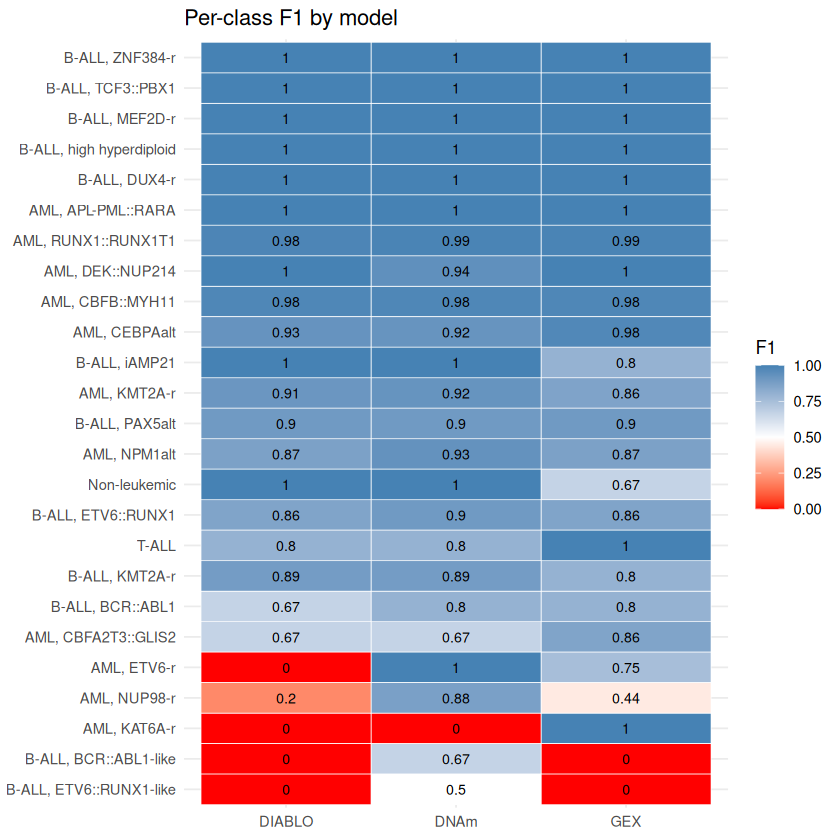

In [14]:
f1_long <- pivot_longer(f1_wide, cols = c("GEX","DNAm","DIABLO"),
                         names_to = "Model", values_to = "F1")

ggplot(f1_long, aes(x = Model, y = reorder(Class, F1), fill = F1)) +
  geom_tile(colour = "white") +
  scale_fill_gradient2(low = "red", mid = "white", high = "steelblue",
                       midpoint = 0.5, limits = c(0, 1)) +
  geom_text(aes(label = round(F1, 2)), size = 3) +
  labs(title = "Per-class F1 by model", x = NULL, y = NULL) +
  theme_minimal()

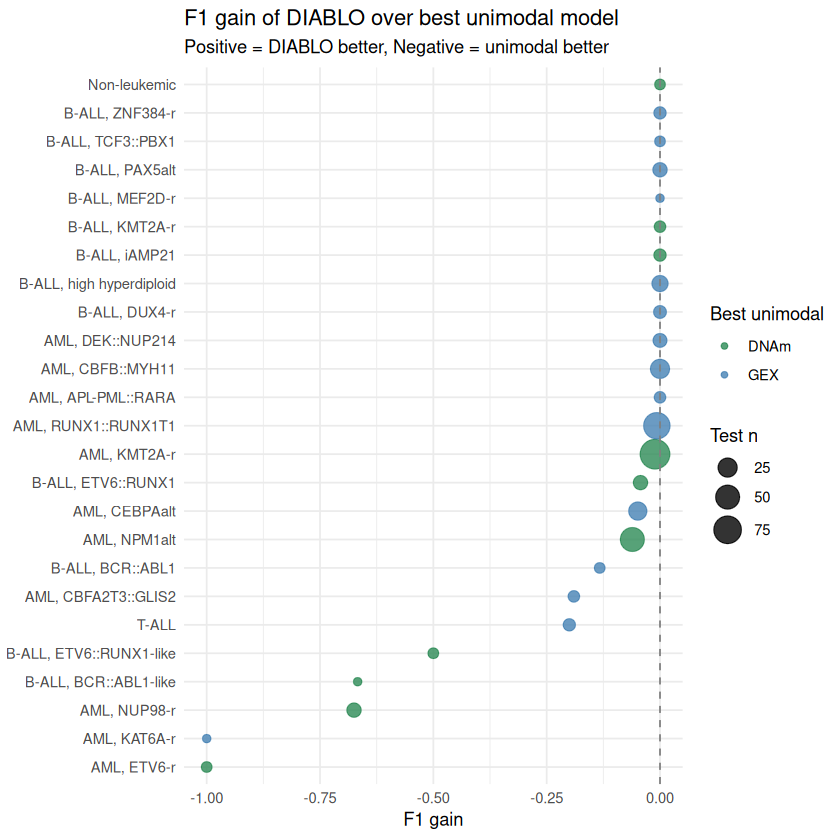

In [15]:
f1_wide <- f1_wide |>
  mutate(
    Best_unimodal    = pmax(GEX, DNAm),
    DIABLO_gain      = DIABLO - Best_unimodal,
    Best_unimodal_name = ifelse(GEX >= DNAm, "GEX", "DNAm")
  )

ggplot(f1_wide, aes(x = DIABLO_gain,
                     y = reorder(Class, DIABLO_gain),
                     colour = Best_unimodal_name,
                     size = n)) +
  geom_point(alpha = 0.8) +
  geom_vline(xintercept = 0, linetype = "dashed", colour = "grey50") +
  scale_colour_manual(values = c(GEX = "steelblue", DNAm = "seagreen"),
                      name = "Best unimodal") +
  scale_size_continuous(range = c(2, 8), name = "Test n") +
  labs(title    = "F1 gain of DIABLO over best unimodal model",
       subtitle = "Positive = DIABLO better, Negative = unimodal better",
       x = "F1 gain", y = NULL) +
  theme_minimal()

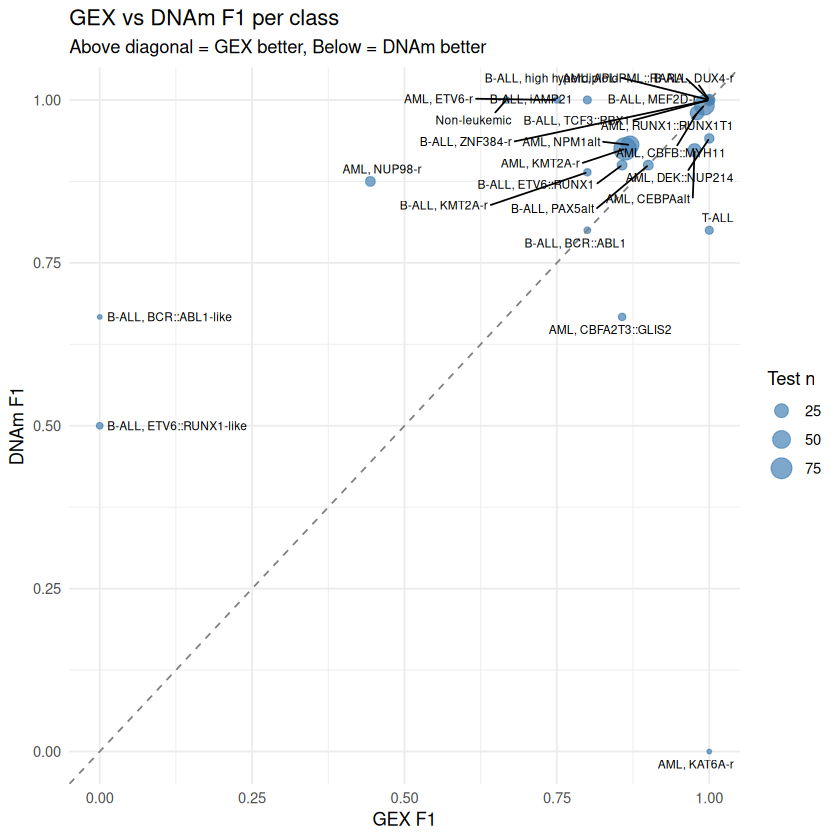

In [16]:
ggplot(f1_wide, aes(x = GEX, y = DNAm, size = n, label = Class)) +
  geom_point(alpha = 0.7, colour = "steelblue") +
  geom_abline(slope = 1, intercept = 0, linetype = "dashed", colour = "grey50") +
  geom_text_repel(size = 2.5, max.overlaps = 20) +
  xlim(0, 1) + ylim(0, 1) +
  labs(title    = "GEX vs DNAm F1 per class",
       subtitle = "Above diagonal = GEX better, Below = DNAm better",
       x = "GEX F1", y = "DNAm F1", size = "Test n") +
  theme_minimal()

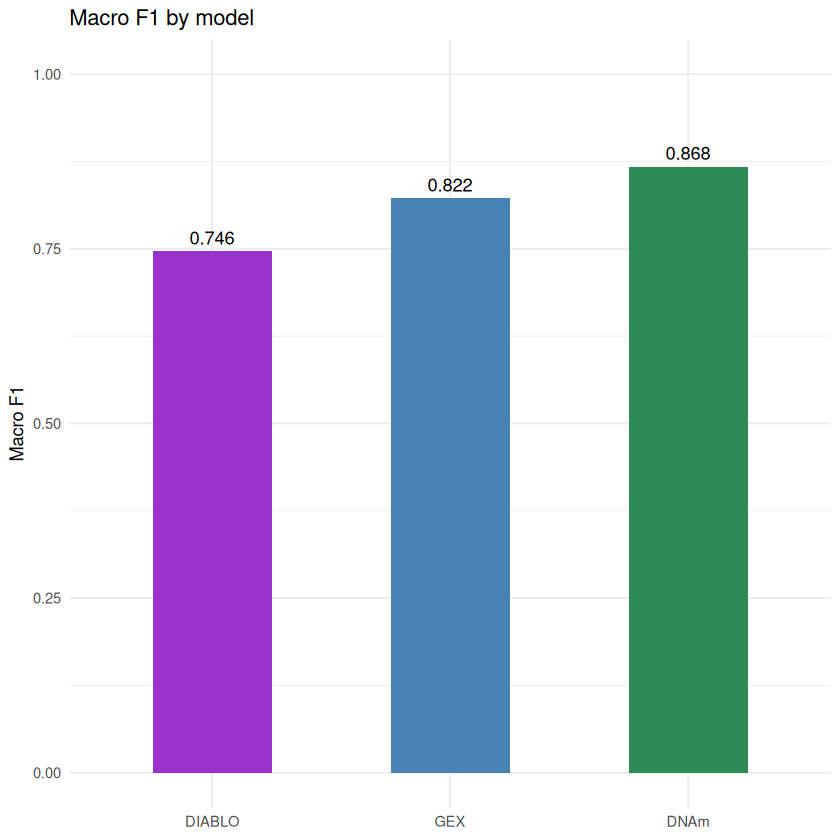

In [17]:
macro_f1 <- f1_all |>
  group_by(Model) |>
  summarise(MacroF1 = mean(F1), .groups = "drop")

ggplot(macro_f1, aes(x = reorder(Model, MacroF1), y = MacroF1, fill = Model)) +
  geom_bar(stat = "identity", width = 0.5) +
  geom_text(aes(label = round(MacroF1, 3)), vjust = -0.5) +
  scale_fill_manual(values = c(GEX = "steelblue",
                                DNAm = "seagreen",
                                DIABLO = "darkorchid")) +
  ylim(0, 1) +
  labs(title = "Macro F1 by model", x = NULL, y = "Macro F1") +
  theme_minimal() +
  theme(legend.position = "none")

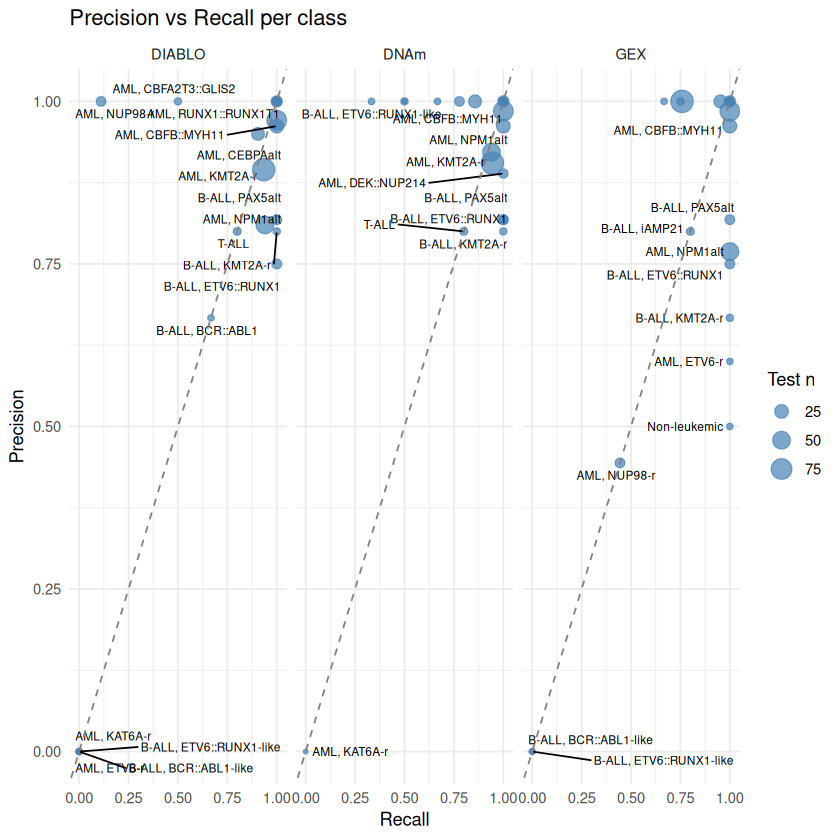

In [18]:
f1_all |>
  left_join(class_n, by = "Class") |>
ggplot(aes(x = Recall, y = Precision, size = n, label = Class)) +
  geom_point(alpha = 0.7, colour = "steelblue") +
  geom_text_repel(size = 2.5, max.overlaps = 15) +
  geom_abline(slope = 1, intercept = 0, linetype = "dashed", colour = "grey50") +
  facet_wrap(~ Model) +
  xlim(0, 1) + ylim(0, 1) +
  labs(title = "Precision vs Recall per class",
       size = "Test n") +
  theme_minimal()

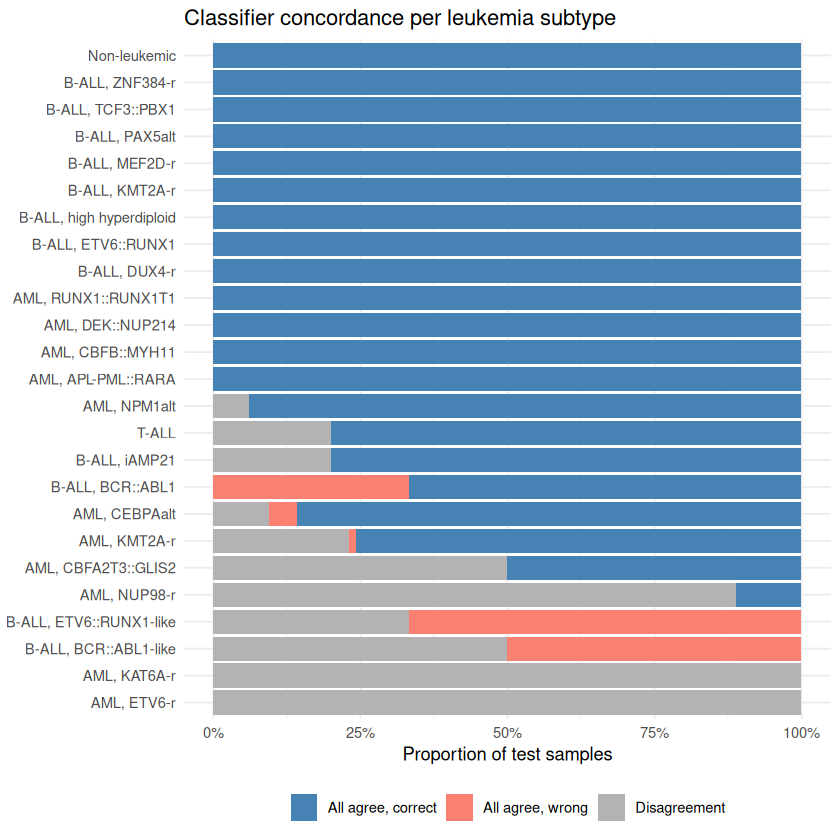

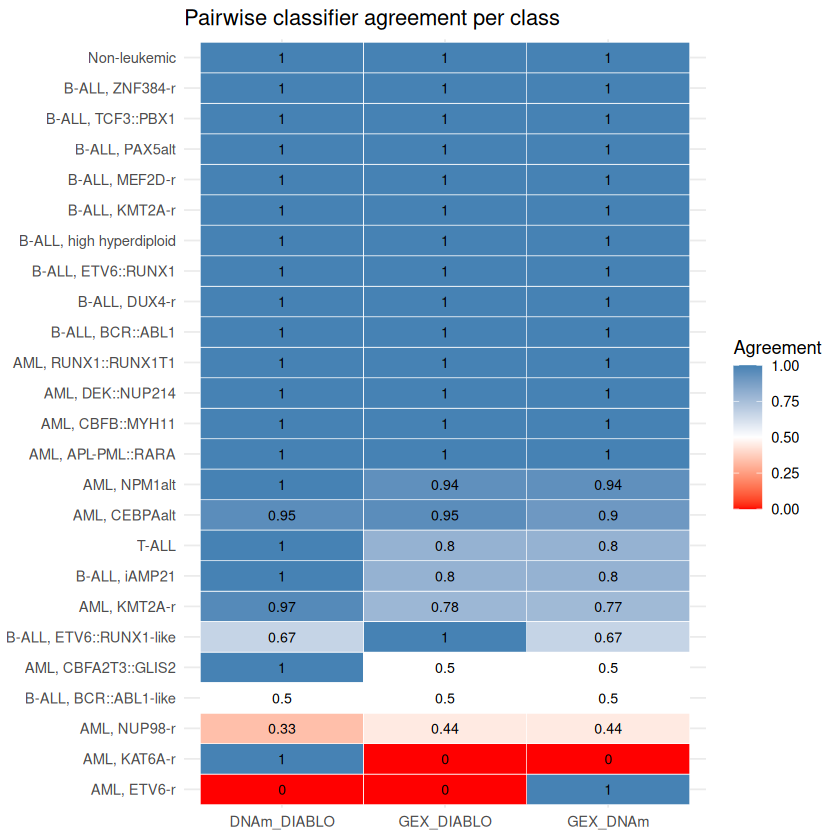

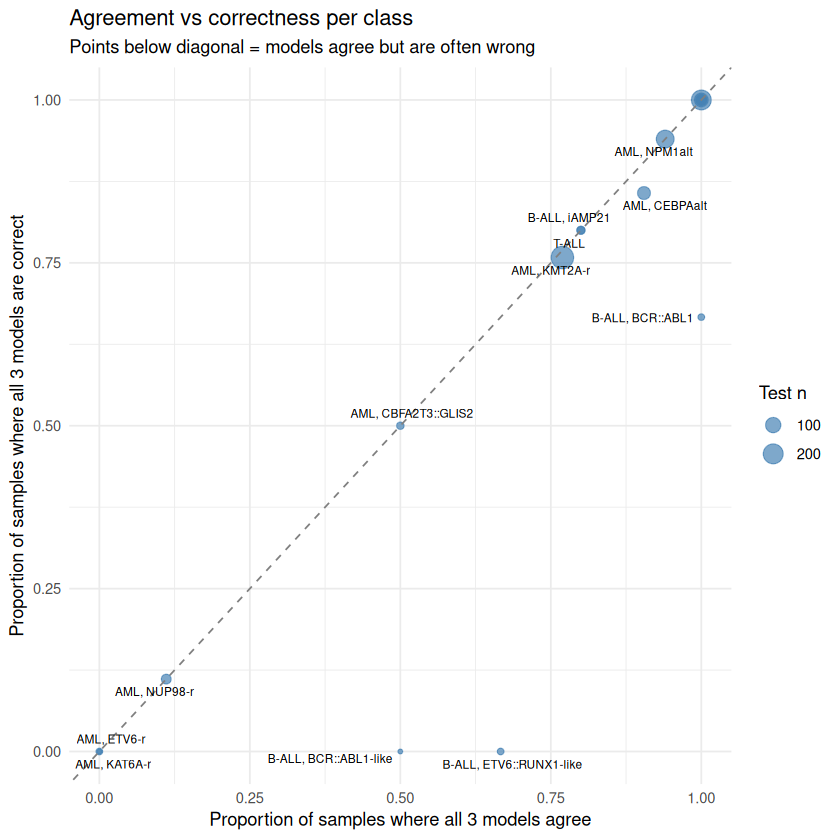

In [20]:
library(ggplot2)
library(dplyr)

# ============================================================
# Compute per-sample concordance
# ============================================================
results_df <- results_df |>
  mutate(
    # How many models agree with each other
    n_agree = (gex_pred == dnam_pred) +
              (gex_pred == diablo_pred) +
              (dnam_pred == diablo_pred),

    # All three agree
    all_agree = gex_pred == dnam_pred & dnam_pred == diablo_pred,

    # All three agree AND correct
    all_correct = all_agree & gex_pred == true_label,

    # Concordance label
    concordance = case_when(
      all_agree & gex_pred == true_label  ~ "All agree, correct",
      all_agree & gex_pred != true_label  ~ "All agree, wrong",
      !all_agree                           ~ "Disagreement"
    )
  )

# ============================================================
# 1. Stacked bar — concordance per true class
# ============================================================
conc_summary <- results_df |>
  group_by(true_label, concordance) |>
  summarise(n = n(), .groups = "drop") |>
  group_by(true_label) |>
  mutate(pct = n / sum(n))

ggplot(conc_summary,
       aes(x = pct,
           y = reorder(true_label, pct * (concordance == "All agree, correct")),
           fill = concordance)) +
  geom_bar(stat = "identity") +
  scale_fill_manual(values = c("All agree, correct" = "steelblue",
                                "All agree, wrong"   = "salmon",
                                "Disagreement"       = "grey70")) +
  scale_x_continuous(labels = scales::percent) +
  labs(title = "Classifier concordance per leukemia subtype",
       x = "Proportion of test samples", y = NULL, fill = NULL) +
  theme_minimal() +
  theme(legend.position = "bottom")

# ============================================================
# 2. Tile plot — pairwise agreement per class
# ============================================================
pairwise <- results_df |>
  group_by(true_label) |>
  summarise(
    GEX_DNAm    = mean(gex_pred == dnam_pred),
    GEX_DIABLO  = mean(gex_pred == diablo_pred),
    DNAm_DIABLO = mean(dnam_pred == diablo_pred),
    .groups = "drop"
  ) |>
  pivot_longer(cols = c("GEX_DNAm","GEX_DIABLO","DNAm_DIABLO"),
               names_to = "Pair", values_to = "Agreement")

ggplot(pairwise, aes(x = Pair,
                      y = reorder(true_label, Agreement),
                      fill = Agreement)) +
  geom_tile(colour = "white") +
  scale_fill_gradient2(low = "red", mid = "white", high = "steelblue",
                       midpoint = 0.5, limits = c(0, 1)) +
  geom_text(aes(label = round(Agreement, 2)), size = 3) +
  labs(title = "Pairwise classifier agreement per class",
       x = NULL, y = NULL, fill = "Agreement") +
  theme_minimal()

# ============================================================
# 3. Scatter — per class: % all-agree vs % correct
# ============================================================
class_conc <- results_df |>
  group_by(true_label) |>
  summarise(
    n          = n(),
    pct_agree  = mean(all_agree),
    pct_correct = mean(gex_pred == true_label &
                       dnam_pred == true_label &
                       diablo_pred == true_label),
    .groups = "drop"
  )

ggplot(class_conc, aes(x = pct_agree, y = pct_correct,
                        size = n, label = true_label)) +
  geom_point(alpha = 0.7, colour = "steelblue") +
  geom_abline(slope = 1, intercept = 0,
              linetype = "dashed", colour = "grey50") +
  geom_text_repel(size = 2.5, max.overlaps = 20) +
  xlim(0, 1) + ylim(0, 1) +
  labs(title    = "Agreement vs correctness per class",
       subtitle = "Points below diagonal = models agree but are often wrong",
       x = "Proportion of samples where all 3 models agree",
       y = "Proportion of samples where all 3 models are correct",
       size = "Test n") +
  theme_minimal()